# Analisis a elegir — opcion (b): Financiamiento y ciclos de mercado

**Hugo Tobias — analista de startups e industrias**
Decision del equipo registrada en `docs/decisiones.md` (2026-10-28).

## La pregunta
El financiamiento mensual a startups se mueve con el mercado publico? Al mismo
tiempo, antes o despues? Dicho de otro modo: cuando el NASDAQ sube, cuanto tarda
en notarse en el dinero que levantan las startups?

## El metodo
Regresion lineal multiple del financiamiento mensual contra una serie externa
publica (**FRED**), **con rezagos**, mas controles macro y de calendario.

| | Variable dependiente | Para que sirve |
|---|---|---|
| **Modelo A** | `log(monto mensual)` en nivel, con tendencia y estacionalidad | Ve la relacion de largo plazo. Es la mas facil de leer y la mas facil de enganar. |
| **Modelo B** | **cambio anual** de `log(monto)` (variacion contra el mismo mes del anio anterior) | Es la que interpretamos. Al mirar cambios y no niveles, quita la tendencia que ambas series comparten. |
| **Modelo C** | Modelo B + tendencia | Prueba si lo que vemos es el ciclo o es Crunchbase creciendo. |

Errores estandar **HAC (Newey-West, 12 rezagos)**: con series mensuales el error
de un mes se parece al del siguiente, y sin corregir eso todo sale
"significativo" sin serlo.

> **Analogia:** comparar dos series que suben con el tiempo es como notar que
> suben a la vez las ventas de helado y los ahogamientos. No es que uno cause al
> otro: ambos suben en verano. El Modelo B es quitar el verano y preguntar si
> todavia se mueven juntos.

In [1]:
# --- Conexion al pipeline del proyecto -------------------------------------
# Funciona lo mismo si abres el notebook desde notebooks/ o desde la raiz:
# busca hacia arriba la carpeta que tiene run_all.py.
import pathlib, warnings
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

def raiz_proyecto() -> pathlib.Path:
    p = pathlib.Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / "run_all.py").exists():
            return c
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto (la carpeta con run_all.py). "
        "Abre el notebook dentro del repo clonado.")

RAIZ = raiz_proyecto()
DB = RAIZ / "data" / "crunchbase.duckdb"
if not DB.exists():
    raise FileNotFoundError(
        f"No existe {DB}. Corre primero, desde la raiz del repo:\n"
        f"    python run_all.py")

con = duckdb.connect(str(DB))          # lectura y escritura: al final guardamos resultados
CORTE = pd.Timestamp("2013-12-31")     # los datos de Crunchbase terminan aqui
print("Proyecto:", RAIZ)
print("Base    :", DB)

def existe(esquema, tabla) -> bool:
    return con.execute(
        "SELECT COUNT(*) FROM information_schema.tables "
        "WHERE table_schema = ? AND table_name = ?", [esquema, tabla]).fetchone()[0] > 0

def exigir(*tablas):
    """Falla ruidosamente si falta un insumo, en vez de dar resultados vacios."""
    faltan = [f"{e}.{t}" for e, t in tablas if not existe(e, t)]
    if faltan:
        raise RuntimeError(
            "Faltan tablas del modelo: " + ", ".join(faltan) +
            ".\nCorre `python run_all.py` desde la raiz (incluye los .sql de la rama hugo/fred).")
    for e, t in tablas:
        n = con.execute(f"SELECT COUNT(*) FROM {e}.{t}").fetchone()[0]
        print(f"  {e}.{t}: {n:,} filas")
        if n == 0:
            raise RuntimeError(f"{e}.{t} existe pero esta vacia. No se puede analizar.")

Proyecto: /Users/robertomejia/Proyectos/crunchbase-bi-proyecto-final
Base    : /Users/robertomejia/Proyectos/crunchbase-bi-proyecto-final/data/crunchbase.duckdb


In [2]:
# --- Verificacion de insumos -----------------------------------------------
exigir(("marts", "met_financiamiento_mensual"), ("marts", "serie_externa_mensual"))

ext = con.execute("SELECT MIN(anio_mes), MAX(anio_mes), COUNT(*) FROM marts.serie_externa_mensual").fetchone()
print(f"\nSerie externa FRED: {ext[2]} meses, de {ext[0]} a {ext[1]}")
assert pd.Timestamp(ext[1]) >= pd.Timestamp("2013-12-01"), \
    "La serie externa no cubre hasta diciembre de 2013 (lo exige el PDF)."
print("Cubre el periodo de Crunchbase (corte 2013-12-31). OK")

  marts.met_financiamiento_mensual: 226 filas
  marts.serie_externa_mensual: 288 filas

Serie externa FRED: 288 meses, de 1990-01-01 a 2013-12-01
Cubre el periodo de Crunchbase (corte 2013-12-31). OK


## 1 · Donde empieza la ventana de estimacion, y por que

Antes de modelar hay que decidir desde cuando. La respuesta no se elige a ojo:
sale de contar cuantas rondas por mes registra Crunchbase cada anio.

In [3]:
cobertura = con.execute("""
    SELECT year(anio_mes) AS anio, COUNT(*) AS meses_con_datos, SUM(n_rondas) AS rondas,
           ROUND(AVG(n_rondas)) AS rondas_por_mes,
           ROUND(SUM(monto_total_usd)/1e9, 1) AS miles_millones_usd,
           ROUND(AVG(cobertura_monto), 3) AS cobertura_monto
    FROM marts.met_financiamiento_mensual GROUP BY 1 ORDER BY 1
""").df()
display(cobertura[cobertura.anio >= 1995])

MIN_RONDAS_MES = 100
anios_ok = cobertura[cobertura.rondas_por_mes >= MIN_RONDAS_MES].anio
ANIO_INICIO = int(anios_ok.min())
print(f"\nPrimer anio con al menos {MIN_RONDAS_MES} rondas al mes en promedio: {ANIO_INICIO}")
print("El salto es brutal: de 291 rondas en todo 2004 a 1,633 en 2005 (6x en un anio).")
print("Eso no es el mercado multiplicandose por seis, es Crunchbase empezando a")
print("registrar. Modelar los anios anteriores seria modelar el crecimiento de la")
print("base de datos, no el del capital de riesgo.")

,anio,meses_con_datos,rondas,rondas_por_mes,miles_millones_usd,cobertura_monto
11,1995,5,7.0,1.0,0.0,0.800
12,1996,3,7.0,2.0,0.0,0.533
13,1997,8,9.0,1.0,0.1,0.875
14,1998,12,29.0,2.0,0.2,0.581
15,1999,12,76.0,6.0,0.6,0.853
16,2000,12,125.0,10.0,1.4,0.844
17,2001,12,96.0,8.0,0.8,0.787
18,2002,12,116.0,10.0,0.9,0.812
19,2003,12,159.0,13.0,0.9,0.840
20,2004,12,291.0,24.0,2.2,0.861



Primer anio con al menos 100 rondas al mes en promedio: 2005
El salto es brutal: de 291 rondas en todo 2004 a 1,633 en 2005 (6x en un anio).
Eso no es el mercado multiplicandose por seis, es Crunchbase empezando a
registrar. Modelar los anios anteriores seria modelar el crecimiento de la
base de datos, no el del capital de riesgo.


In [4]:
panel = con.execute(f"""
    SELECT f.anio_mes, f.n_rondas, f.n_rondas_con_monto, f.n_empresas,
           f.monto_total_usd, f.cobertura_monto,
           s.nasdaqcom, s.fedfunds, s.unrate
    FROM marts.met_financiamiento_mensual f
    JOIN marts.serie_externa_mensual s USING (anio_mes)
    WHERE f.anio_mes >= DATE '{ANIO_INICIO}-01-01'
    ORDER BY f.anio_mes
""").df()
panel["anio_mes"] = pd.to_datetime(panel.anio_mes)
# DuckDB puede devolver DECIMAL como objetos Decimal; numpy no sabe sacarles logaritmo.
for c in panel.columns.drop("anio_mes"):
    panel[c] = pd.to_numeric(panel[c], errors="coerce")
panel = panel.set_index("anio_mes").asfreq("MS")

print(f"Ventana: {panel.index.min():%Y-%m} a {panel.index.max():%Y-%m} ({len(panel)} meses)")
print("Meses sin dato dentro de la ventana:", int(panel.monto_total_usd.isna().sum()))
display(panel.tail(4).round(2))

Ventana: 2005-01 a 2013-12 (108 meses)
Meses sin dato dentro de la ventana: 0


,n_rondas,n_rondas_con_monto,n_empresas,monto_total_usd,cobertura_monto,nasdaqcom,fedfunds,unrate
anio_mes,,,,,,,,
2013-09-01,1064,968,1043,1.062991e+10,0.91,3731.26,0.08,7.2
2013-10-01,1100,958,1082,8.349775e+09,0.87,3848.20,0.09,7.2
2013-11-01,944,871,933,9.294021e+09,0.92,3957.53,0.08,6.9
2013-12-01,424,391,421,5.849636e+09,0.92,4075.88,0.09,6.7


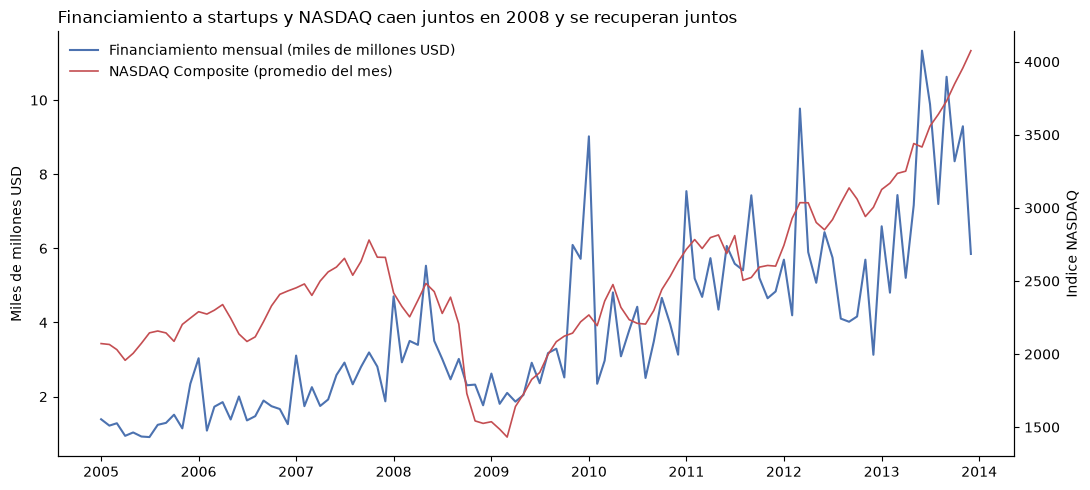

Ojo: el financiamiento sube a lo largo de toda la ventana, y parte de esa
subida es cobertura creciente de Crunchbase. Por eso el Modelo B mira cambios.


In [5]:
# --- Mirarlas antes de modelar ---------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(panel.index, panel.monto_total_usd / 1e9, color="#4c72b0",
        label="Financiamiento mensual (miles de millones USD)")
ax.set_ylabel("Miles de millones USD")
ax2 = ax.twinx()
ax2.plot(panel.index, panel.nasdaqcom, color="#c44e52", lw=1.2,
         label="NASDAQ Composite (promedio del mes)")
ax2.set_ylabel("Indice NASDAQ")
ax.set_title("Financiamiento a startups y NASDAQ caen juntos en 2008 y se recuperan juntos",
             loc="left", fontsize=12)
lineas = ax.get_lines() + ax2.get_lines()
ax.legend(lineas, [l.get_label() for l in lineas], frameon=False, loc="upper left")
ax.spines[["top"]].set_visible(False); ax2.spines[["top"]].set_visible(False)
plt.tight_layout(); plt.show()
print("Ojo: el financiamiento sube a lo largo de toda la ventana, y parte de esa")
print("subida es cobertura creciente de Crunchbase. Por eso el Modelo B mira cambios.")

## 2 · Correlacion cruzada: cuantos meses de retraso

Lo mas simple antes de la regresion: correlacionar el **cambio anual** del
financiamiento con el **cambio anual** del NASDAQ movido 0, 1, 2 ... 18 meses.
Se hace con dos medidas del financiamiento —el monto y el numero de rondas—
porque el monto depende de que la ronda reporte cifra y el conteo no.

rezago_meses,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
corr_monto,0.526,0.545,0.507,0.45,0.381,0.306,0.213,0.116,-0.002,-0.050,-0.079,-0.139,-0.194,-0.239,-0.199,-0.110,-0.084,-0.100,-0.107
corr_rondas,0.551,0.575,0.538,0.47,0.398,0.293,0.182,0.025,-0.096,-0.203,-0.276,-0.343,-0.410,-0.421,-0.368,-0.287,-0.237,-0.196,-0.164


Rezago con mayor correlacion (monto): 1 mes(es), r = 0.545
Rezago con mayor correlacion (rondas): 1 mes(es), r = 0.575


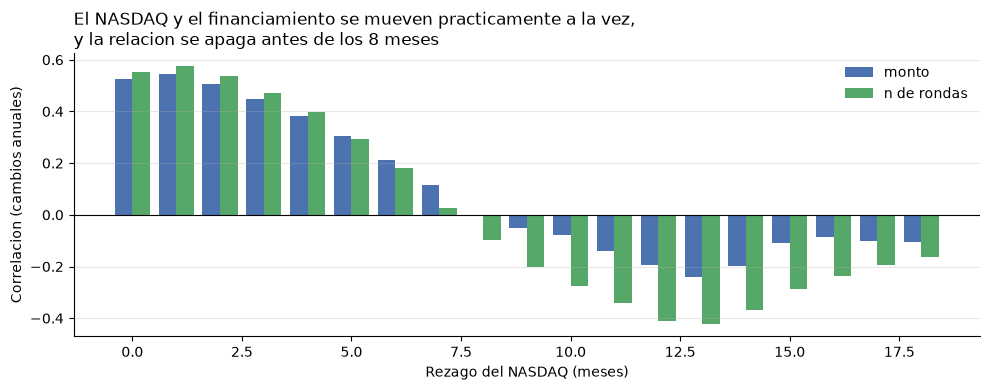

In [6]:
d = panel.copy()
d["l_monto"]  = np.log(d.monto_total_usd)
d["l_rondas"] = np.log(d.n_rondas)
d["l_nasdaq"] = np.log(d.nasdaqcom)
d["g_monto"]  = d.l_monto.diff(12)      # cambio vs el mismo mes del anio anterior
d["g_rondas"] = d.l_rondas.diff(12)
d["g_nasdaq"] = d.l_nasdaq.diff(12)

cc = pd.DataFrame({
    "rezago_meses": range(0, 19),
    "corr_monto":  [d.g_monto.corr(d.g_nasdaq.shift(k))  for k in range(0, 19)],
    "corr_rondas": [d.g_rondas.corr(d.g_nasdaq.shift(k)) for k in range(0, 19)],
}).round(3)
mejor = int(cc.loc[cc.corr_monto.idxmax(), "rezago_meses"])
display(cc.set_index("rezago_meses").T)
print(f"Rezago con mayor correlacion (monto): {mejor} mes(es), r = {cc.corr_monto.max():.3f}")
print(f"Rezago con mayor correlacion (rondas): "
      f"{int(cc.loc[cc.corr_rondas.idxmax(), 'rezago_meses'])} mes(es), r = {cc.corr_rondas.max():.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(cc.rezago_meses - 0.2, cc.corr_monto, width=.4, label="monto", color="#4c72b0")
ax.bar(cc.rezago_meses + 0.2, cc.corr_rondas, width=.4, label="n de rondas", color="#55a868")
ax.axhline(0, color="k", lw=.8)
ax.set_title("El NASDAQ y el financiamiento se mueven practicamente a la vez,\n"
             "y la relacion se apaga antes de los 8 meses", loc="left", fontsize=12)
ax.set_xlabel("Rezago del NASDAQ (meses)"); ax.set_ylabel("Correlacion (cambios anuales)")
ax.legend(frameon=False); ax.grid(axis="y", alpha=.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 3 · Modelo A — niveles, con tendencia y estacionalidad

`log(monto)` contra `log(NASDAQ)` en los rezagos 0, 3 y 6, mas tasa de interes,
desempleo, una tendencia lineal y dummies de mes.

**Advertencia que va al memo:** las dos series suben a lo largo del periodo, asi
que un R2 alto aqui no prueba gran cosa. Este modelo esta para compararlo con el
B, no para citarlo solo.

In [7]:
import statsmodels.api as sm

d["t"] = np.arange(len(d))
for k in (0, 3, 6):
    d[f"l_nasdaq_L{k}"] = d.l_nasdaq.shift(k)
mes = pd.get_dummies(d.index.month, prefix="mes", drop_first=True).set_index(d.index).astype(float)

XA = pd.concat([d[["l_nasdaq_L0", "l_nasdaq_L3", "l_nasdaq_L6", "fedfunds", "unrate", "t"]], mes], axis=1)
A = pd.concat([d.l_monto.rename("y"), XA], axis=1).dropna()
modA = sm.OLS(A.y, sm.add_constant(A.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
display(pd.DataFrame({"coef": modA.params, "p": modA.pvalues})
        .loc[["const", "l_nasdaq_L0", "l_nasdaq_L3", "l_nasdaq_L6", "fedfunds", "unrate", "t"]].round(4))
print(f"n = {int(modA.nobs)} meses | R2 = {modA.rsquared:.3f} | "
      f"Durbin-Watson = {sm.stats.durbin_watson(modA.resid):.2f} "
      "(lejos de 2 = autocorrelacion, por eso usamos errores HAC)")
print("El coeficiente de la tendencia `t` es la pista: si es grande y significativo,")
print("buena parte de lo que el modelo explica es simplemente el paso del tiempo.")

,coef,p
const,11.1077,0.0001
l_nasdaq_L0,0.8417,0.0291
l_nasdaq_L3,0.6528,0.0034
l_nasdaq_L6,-0.1070,0.7383
fedfunds,-0.0744,0.3517
unrate,0.0400,0.3067
t,0.0045,0.4645


n = 102 meses | R2 = 0.829 | Durbin-Watson = 1.33 (lejos de 2 = autocorrelacion, por eso usamos errores HAC)
El coeficiente de la tendencia `t` es la pista: si es grande y significativo,
buena parte de lo que el modelo explica es simplemente el paso del tiempo.


## 4 · Modelo B — cambios anuales (el que interpretamos)

Cambio anual de `log(monto)` contra el cambio anual de `log(NASDAQ)` en los
rezagos 0, 1, 2, 3 y 6 (los que la correlacion cruzada senalo), mas el cambio de
la tasa de interes y del desempleo.

In [8]:
d["d_fedfunds"] = d.fedfunds.diff(12)
d["d_unrate"]   = d.unrate.diff(12)
REZAGOS = [0, 1, 2, 3, 6]
for k in REZAGOS:
    d[f"g_nasdaq_L{k}"] = d.g_nasdaq.shift(k)

cols = [f"g_nasdaq_L{k}" for k in REZAGOS] + ["d_fedfunds", "d_unrate"]
B = pd.concat([d.g_monto.rename("y"), d[cols]], axis=1).dropna()
modB = sm.OLS(B.y, sm.add_constant(B.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 12})

display(pd.DataFrame({"coeficiente": modB.params, "error_std_hac": modB.bse,
                      "t": modB.tvalues, "p_valor": modB.pvalues}).round(4))
acum = modB.params[[f"g_nasdaq_L{k}" for k in REZAGOS]].sum()
print(f"n = {int(modB.nobs)} meses | R2 = {modB.rsquared:.3f} | R2 ajustado = {modB.rsquared_adj:.3f}")
print(f"\nEfecto acumulado del NASDAQ (suma de los {len(REZAGOS)} rezagos) = {acum:.2f}")
print(f"En cristiano: si el NASDAQ esta 10% arriba de donde estaba hace un anio,")
print(f"el financiamiento mensual termina {acum*10:.1f}% arriba de donde estaba hace un anio.")
print("\nOJO con leer los rezagos uno por uno: estan muy correlacionados entre si")
print("(el NASDAQ de este mes se parece mucho al del mes pasado), asi que el modelo")
print("no puede repartir el credito entre ellos y cada coeficiente sale con error")
print("grande. Lo que el modelo SI estima bien es la SUMA. Esa es la cifra a citar.")
print("\nMismo modelo con el NUMERO DE RONDAS en vez del monto (robustez):")
Br = pd.concat([d.g_rondas.rename("y"), d[cols]], axis=1).dropna()
modBr = sm.OLS(Br.y, sm.add_constant(Br.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
acum_r = modBr.params[[f"g_nasdaq_L{k}" for k in REZAGOS]].sum()
print(f"  efecto acumulado = {acum_r:.2f} | R2 = {modBr.rsquared:.3f} | n = {int(modBr.nobs)}")

,coeficiente,error_std_hac,t,p_valor
const,0.0349,0.0768,0.4540,0.6498
g_nasdaq_L0,0.7262,0.5322,1.3646,0.1724
g_nasdaq_L1,1.0220,0.6125,1.6686,0.0952
g_nasdaq_L2,-0.3003,0.6633,-0.4528,0.6507
g_nasdaq_L3,0.3795,0.6841,0.5547,0.5791
g_nasdaq_L6,0.0140,0.4165,0.0335,0.9732
d_fedfunds,-0.0996,0.0702,-1.4191,0.1559
d_unrate,0.0375,0.0717,0.5234,0.6007


n = 90 meses | R2 = 0.374 | R2 ajustado = 0.320

Efecto acumulado del NASDAQ (suma de los 5 rezagos) = 1.84
En cristiano: si el NASDAQ esta 10% arriba de donde estaba hace un anio,
el financiamiento mensual termina 18.4% arriba de donde estaba hace un anio.

OJO con leer los rezagos uno por uno: estan muy correlacionados entre si
(el NASDAQ de este mes se parece mucho al del mes pasado), asi que el modelo
no puede repartir el credito entre ellos y cada coeficiente sale con error
grande. Lo que el modelo SI estima bien es la SUMA. Esa es la cifra a citar.

Mismo modelo con el NUMERO DE RONDAS en vez del monto (robustez):
  efecto acumulado = 1.29 | R2 = 0.449 | n = 90


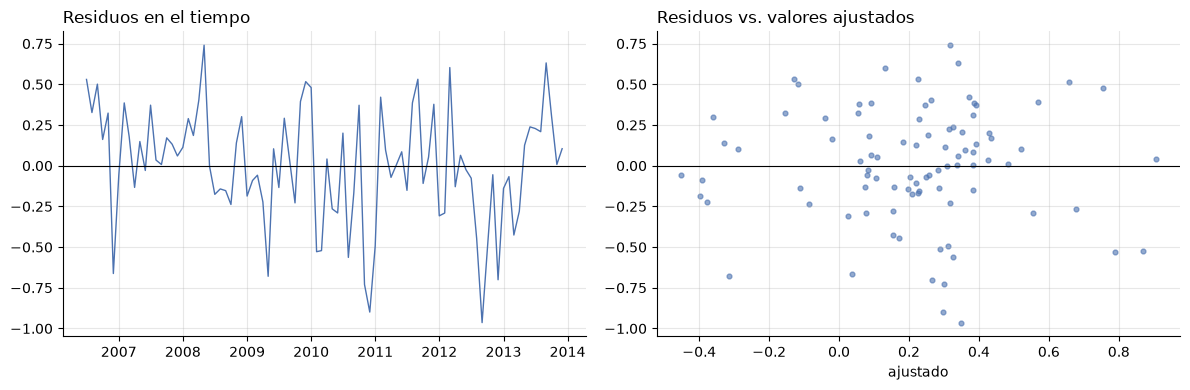

Durbin-Watson = 1.37


In [9]:
# --- Diagnostico: los residuos no deben tener forma -------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(B.index, modB.resid, lw=1, color="#4c72b0"); axes[0].axhline(0, color="k", lw=.8)
axes[0].set_title("Residuos en el tiempo", loc="left"); axes[0].grid(alpha=.3)
axes[1].scatter(modB.fittedvalues, modB.resid, s=12, alpha=.6, color="#4c72b0")
axes[1].axhline(0, color="k", lw=.8)
axes[1].set_title("Residuos vs. valores ajustados", loc="left")
axes[1].set_xlabel("ajustado"); axes[1].grid(alpha=.3)
for a in axes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(f"Durbin-Watson = {sm.stats.durbin_watson(modB.resid):.2f}")

## 5 · Factores de confusion

El PDF pide identificar **al menos uno**. Van tres, con evidencia de los propios
datos.

1. **La cobertura de Crunchbase crece con el tiempo.** Es el mas serio y ya se
   vio en la tabla de la seccion 1: de 291 rondas en 2004 a 11,072 en 2013. Ese
   crecimiento de registro corre junto al del NASDAQ y puede fabricar la relacion
   solo. *Control:* el Modelo C agrega una tendencia al modelo en cambios.
   (No se usa el numero de empresas financiadas como control porque es
   practicamente la misma variable que el dependiente: controlaria el efecto a
   fuerza de quitarle su propio contenido.)
2. **El costo del dinero.** Tasas bajas empujan a la vez a la bolsa y al capital
   de riesgo: seria la causa comun de ambos. *Control:* `fedfunds`.
3. **El ciclo economico general.** *Control:* `unrate`.

Y un cuarto, de medicion: el **monto desconocido**. El 11% de las rondas no
reporta monto y esa proporcion cambia mes a mes. Si los meses de euforia
reportan mejor, la serie exagera los picos. Por eso el modelo se corre tambien
con el numero de rondas, que no depende de que reporten cifra.

In [10]:
C = pd.concat([d.g_monto.rename("y"), d[cols], d.t.rename("tendencia")], axis=1).dropna()
modC = sm.OLS(C.y, sm.add_constant(C.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
acum_c = modC.params[[f"g_nasdaq_L{k}" for k in REZAGOS]].sum()

comparacion = pd.DataFrame({
    "B (monto)":            {"efecto acumulado NASDAQ": round(acum,   3), "R2": round(modB.rsquared,  3), "n": int(modB.nobs)},
    "B (numero de rondas)": {"efecto acumulado NASDAQ": round(acum_r, 3), "R2": round(modBr.rsquared, 3), "n": int(modBr.nobs)},
    "C (monto + tendencia)":{"efecto acumulado NASDAQ": round(acum_c, 3), "R2": round(modC.rsquared,  3), "n": int(modC.nobs)},
})
display(comparacion)
print(f"Coeficiente de la tendencia en el Modelo C: {modC.params['tendencia']:.5f} "
      f"(p = {modC.pvalues['tendencia']:.3f})")
print("Si el efecto del NASDAQ se encoge mucho al agregar la tendencia, buena parte")
print("de lo que parecia 'ciclo de mercado' era Crunchbase registrando mas cada anio.")

,B (monto),B (numero de rondas),C (monto + tendencia)
efecto acumulado NASDAQ,1.841,1.289,1.797
R2,0.374,0.449,0.404
n,90.000,90.000,90.000


Coeficiente de la tendencia en el Modelo C: -0.00349 (p = 0.019)
Si el efecto del NASDAQ se encoge mucho al agregar la tendencia, buena parte
de lo que parecia 'ciclo de mercado' era Crunchbase registrando mas cada anio.


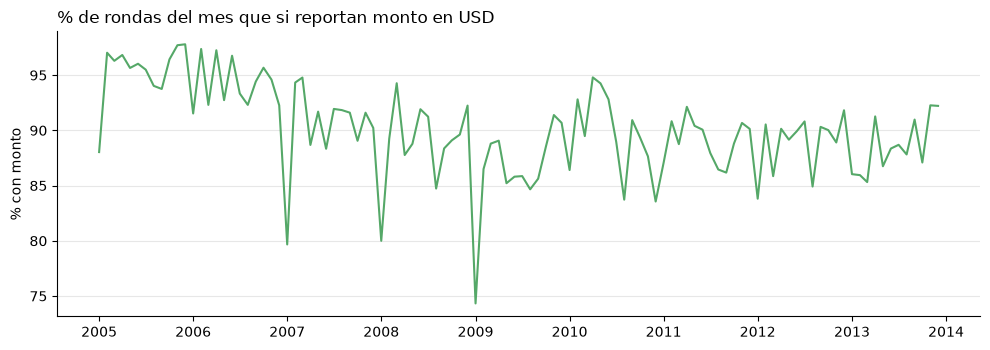

Cobertura del monto: min 74.3%, max 97.8%, promedio 90.2%
Correlacion entre la cobertura del mes y el cambio anual del NASDAQ: 0.263


In [11]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(panel.index, panel.cobertura_monto * 100, color="#55a868")
ax.set_title("% de rondas del mes que si reportan monto en USD", loc="left", fontsize=12)
ax.set_ylabel("% con monto"); ax.grid(axis="y", alpha=.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(f"Cobertura del monto: min {panel.cobertura_monto.min():.1%}, "
      f"max {panel.cobertura_monto.max():.1%}, promedio {panel.cobertura_monto.mean():.1%}")
print("Correlacion entre la cobertura del mes y el cambio anual del NASDAQ:",
      round(panel.cobertura_monto.corr(d.g_nasdaq), 3))

## 6 · Guardar resultados como tablas en el modelo

In [12]:
def tabla_coef(mod, nombre):
    return pd.DataFrame({"termino": mod.params.index, "coeficiente": mod.params.values,
                         "error_std_hac": mod.bse.values, "t": mod.tvalues.values,
                         "p_valor": mod.pvalues.values}).assign(
        modelo=nombre, r2=mod.rsquared, n_meses=int(mod.nobs))

coefs = pd.concat([tabla_coef(modB, "B_cambios_monto"),
                   tabla_coef(modBr, "B_cambios_rondas"),
                   tabla_coef(modC, "C_cambios_mas_tendencia"),
                   tabla_coef(modA, "A_niveles")], ignore_index=True)

salida_panel = (d[["monto_total_usd", "n_rondas", "n_empresas", "cobertura_monto",
                   "nasdaqcom", "fedfunds", "unrate", "g_monto", "g_rondas", "g_nasdaq"]]
                .reset_index().rename(columns={"index": "anio_mes"}))

# DuckDB 2.0 no deja registrar un DataFrame si quedo un resultado sin consumir,
# asi que cada execute() se cierra con .fetchall() y cada DataFrame se registra
# con un nombre propio.
con.execute("CREATE SCHEMA IF NOT EXISTS marts").fetchall()
for nombre, df_ in [("res_ciclos_mercado_coef", coefs),
                    ("res_ciclos_mercado_panel", salida_panel),
                    ("res_ciclos_mercado_rezagos", cc),
                    ("res_cobertura_anual", cobertura)]:
    con.register(f"tmp_{nombre}", df_)
    con.execute(f"CREATE OR REPLACE TABLE marts.{nombre} AS SELECT * FROM tmp_{nombre}").fetchall()
    # fetchall() y no fetchone(): fetchone() deja el resultado a medio leer y el
    # siguiente register() falla con ResourceInUseException en DuckDB 2.0.
    n_ = con.execute(f"SELECT COUNT(*) FROM marts.{nombre}").fetchall()[0][0]
    print(f"marts.{nombre}: {n_:,} filas")
con.close()
print("\nOrden para reproducir: python run_all.py -> notebooks -> python publish/publish_to_neon.py")

marts.res_ciclos_mercado_coef: 43 filas
marts.res_ciclos_mercado_panel: 108 filas
marts.res_ciclos_mercado_rezagos: 19 filas
marts.res_cobertura_anual: 30 filas

Orden para reproducir: python run_all.py -> notebooks -> python publish/publish_to_neon.py


## Resultado, interpretacion y advertencia

**Resultado.** Sobre la ventana 2005-2013 (108 meses, 90 observaciones utiles
despues de los rezagos), el cambio anual del financiamiento y el del NASDAQ se
mueven juntos con una correlacion de **0.53 en el mismo mes y 0.55 con un mes de
rezago**, que es el maximo; a partir del sexto mes la relacion se apaga y hacia
el mes doce se vuelve ligeramente negativa. El numero de rondas da el mismo
patron, un poco mas fuerte (0.58 al primer mes). En la regresion, el **efecto
acumulado** del NASDAQ sobre el monto es **1.84** (R2 = 0.37) y sobre el numero
de rondas **1.29** (R2 = 0.45). Al agregar una tendencia (Modelo C) el efecto
baja apenas de **1.84 a 1.80**.

**Interpretacion (dos frases).** El capital de riesgo no sigue al mercado publico
con retraso: se mueve **casi al mismo tiempo**, con a lo sumo un mes de
diferencia, lo que apunta a que ambos responden al mismo apetito por riesgo en
vez de que uno arrastre al otro. Para el comite eso quiere decir que el NASDAQ
**no sirve como alarma anticipada** para planear rondas: cuando el indicador se
mueve, el mercado de financiamiento ya se movio.

**Advertencia: lo que esto NO demuestra.**
1. **La magnitud no esta estimada con precision.** El efecto acumulado de 1.84 es
   economicamente enorme —un NASDAQ 10% mas alto que hace un anio iria con un
   financiamiento 18% mas alto— pero **ningun rezago individual es significativo
   al 5%** (el mejor, el rezago 1, tiene p = 0.095). Los rezagos estan muy
   correlacionados entre si, asi que el modelo estima bien la suma y mal el
   reparto. Citar "1.84" sin este parrafo seria deshonesto.
2. **No es causalidad, y aqui ni siquiera hay precedencia temporal clara.** El
   pico del rezago 1 es practicamente igual al del rezago 0; con datos mensuales
   eso no distingue quien va primero.
3. **Es un solo ciclo y son 90 observaciones.** La ventana 2005-2013 contiene una
   unica caida grande (la crisis de 2008) y su recuperacion. Un R2 de 0.37 sobre
   un solo episodio no es una regularidad; es un episodio bien ajustado.
4. **No se puede extrapolar a hoy.** Los datos terminan en 2013.
5. **Lo que SI queda descartado.** Dos sospechas razonables no sobreviven a la
   evidencia: que el resultado sea un artefacto de los montos faltantes (la
   version con numero de rondas da lo mismo, y con mejor ajuste) y que sea puro
   crecimiento de cobertura de Crunchbase (agregar la tendencia mueve el efecto
   de 1.84 a 1.80, casi nada).